In [1]:
from ultralytics import YOLO
import torch

print("CUDA:", torch.cuda.is_available())
model = YOLO("yolov8n.pt")  # 第一次会自动下载权重
print("Model loaded.")


CUDA: True
Model loaded.


In [9]:
import json
import os
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# 路径按你服务器实际情况改
JSON_PATH = "train.json"
IMG_ROOT = "images"  # 放 3000 张图片的目录

with open(JSON_PATH, "r") as f:
    data = json.load(f)

images = data["images"]
annotations = data["annotations"]
categories = data["categories"]

# 映射
id2img = {img["id"]: img for img in images}
id2cat = {c["id"]: c["name"] for c in categories}

# 每张图对应的标注列表
img2anns = {}
for ann in annotations:
    img_id = ann["image_id"]
    img2anns.setdefault(img_id, []).append(ann)

print("num images:", len(images))
print("num annotations:", len(annotations))
print("categories:", id2cat)


num images: 3000
num annotations: 3604
categories: {0: 'normal', 1: 'anomaly'}


Counter({1: 2619, 2: 265, 3: 66, 4: 20, 5: 13, 7: 10, 6: 7})


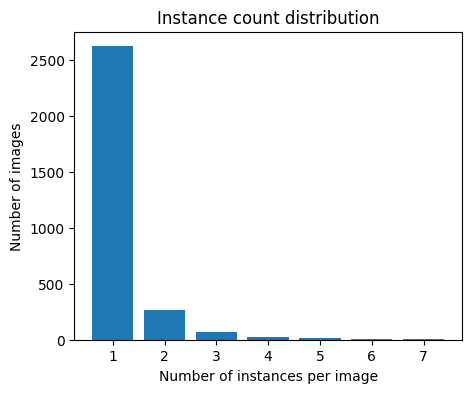

In [8]:
# 统计每张图的目标数
instance_counts = []

for img in images:
    img_id = img["id"]
    anns = img2anns.get(img_id, [])
    instance_counts.append(len(anns))

# 用 Counter 看一下分布
from collections import Counter
count_dist = Counter(instance_counts)
print(count_dist)

# 画柱状图
plt.figure(figsize=(5,4))
plt.bar(count_dist.keys(), count_dist.values())
plt.xlabel("Number of instances per image")
plt.ylabel("Number of images")
plt.title("Instance count distribution")
plt.show()


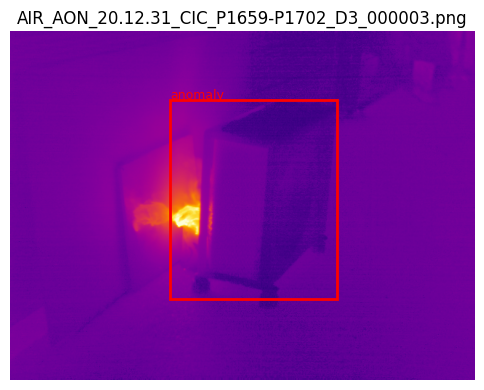

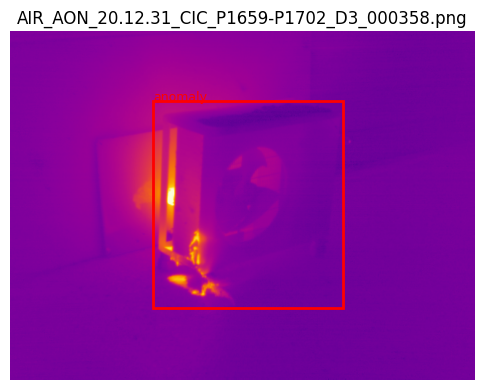

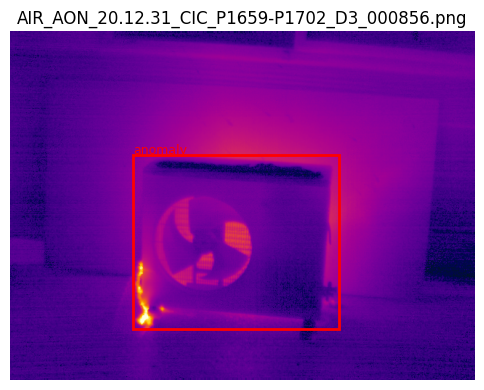

In [10]:
def show_image_with_boxes(img_index):
    img_info = images[img_index]
    img_id = img_info["id"]
    file_name = img_info["file_name"]
    img_path = os.path.join(IMG_ROOT, file_name)

    im = Image.open(img_path).convert("RGB")

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(im)

    anns = img2anns.get(img_id, [])
    for ann in anns:
        x, y, w, h = ann["bbox"]  # COCO: [x,y,w,h]
        cat_id = ann["category_id"]
        cat_name = id2cat[cat_id]

        color = "red" if "anom" in cat_name.lower() else "lime"

        rect = patches.Rectangle(
            (x, y), w, h,
            linewidth=2, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(x, y - 2, cat_name, color=color, fontsize=9)

    plt.axis("off")
    plt.title(file_name)
    plt.show()

# 看几张
show_image_with_boxes(0)
show_image_with_boxes(10)
show_image_with_boxes(20)


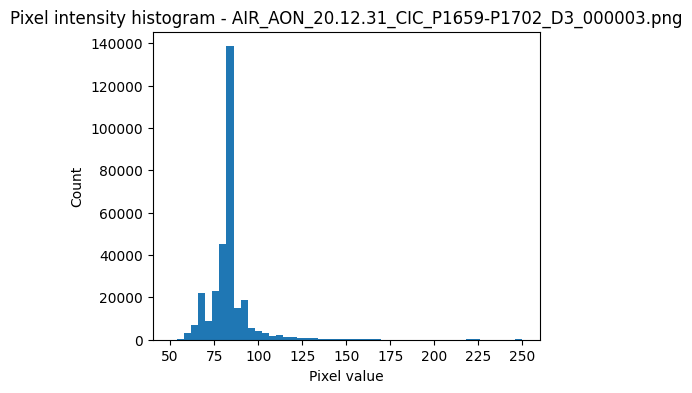

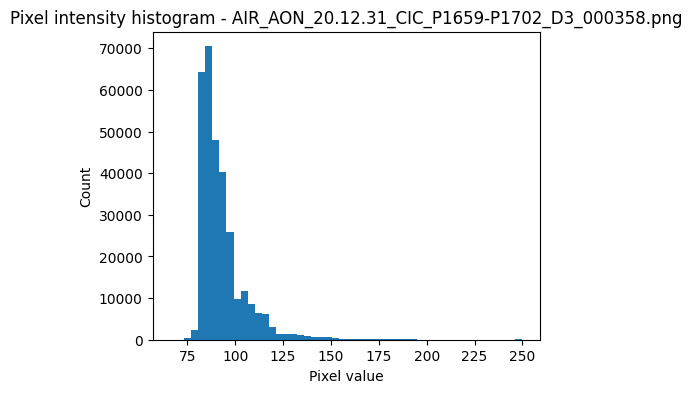

In [11]:
import cv2

def show_pixel_hist(img_index):
    img_info = images[img_index]
    file_name = img_info["file_name"]
    img_path = os.path.join(IMG_ROOT, file_name)

    # 用 cv2 灰度读入
    gray = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

    plt.figure(figsize=(5,4))
    plt.hist(gray.ravel(), bins=50)
    plt.title(f"Pixel intensity histogram - {file_name}")
    plt.xlabel("Pixel value")
    plt.ylabel("Count")
    plt.show()

show_pixel_hist(0)
show_pixel_hist(10)


In [16]:
label_root = "labels_all"
os.makedirs(label_root, exist_ok=True)

# 先看看 annotations 里到底有哪些 category_id
unique_cat_ids = sorted({ann["category_id"] for ann in annotations})
print("category_ids in annotations:", unique_cat_ids)

# 假设最小的 id 是 normal，其余都当成 anomaly
normal_id = unique_cat_ids[0]
print("Treat category_id =", normal_id, "as normal (class 0). Others -> anomaly (class 1).")

cat_id_to_yolo = {}
for cid in unique_cat_ids:
    if cid == normal_id:
        cat_id_to_yolo[cid] = 0  # normal
    else:
        cat_id_to_yolo[cid] = 1  # anomaly

print("cat_id_to_yolo mapping:", cat_id_to_yolo)


labels_per_img = {img["id"]: [] for img in images}

for ann in annotations:
    img_id = ann["image_id"]
    img_info = id2img[img_id]

    W, H = img_info["width"], img_info["height"]
    x, y, w, h = ann["bbox"]

    cx = (x + w / 2) / W
    cy = (y + h / 2) / H
    nw = w / W
    nh = h / H

    cid = ann["category_id"]

    # 安全起见，再检查一次
    if cid not in cat_id_to_yolo:
        # 如果真的遇到没映射的，就直接当成 anomaly
        print(f"[WARN] unknown category_id {cid}, treat as anomaly(1)")
        cls = 1
    else:
        cls = cat_id_to_yolo[cid]

    labels_per_img[img_id].append((cls, cx, cy, nw, nh))


for img in images:
    img_id = img["id"]
    base = os.path.splitext(img["file_name"])[0]
    label_path = os.path.join(label_root, base + ".txt")

    lines = []
    for cls, cx, cy, nw, nh in labels_per_img[img_id]:
        lines.append(f"{cls} {cx:.6f} {cy:.6f} {nw:.6f} {nh:.6f}")

    with open(label_path, "w") as f:
        f.write("\n".join(lines))


category_ids in annotations: [0, 1, 3, 4]
Treat category_id = 0 as normal (class 0). Others -> anomaly (class 1).
cat_id_to_yolo mapping: {0: 0, 1: 1, 3: 1, 4: 1}


In [19]:
import os

DATA_ROOT = "dataset"

img_train_dir = os.path.join(DATA_ROOT, "images/train")
img_val_dir   = os.path.join(DATA_ROOT, "images/val")
lbl_train_dir = os.path.join(DATA_ROOT, "labels/train")
lbl_val_dir   = os.path.join(DATA_ROOT, "labels/val")

print("train images:", len(os.listdir(img_train_dir)))
print("val images:  ", len(os.listdir(img_val_dir)))
print("train labels:", len(os.listdir(lbl_train_dir)))
print("val labels:  ", len(os.listdir(lbl_val_dir)))

print("\nExample train image:", os.listdir(img_train_dir)[:3])
print("Example train label:", os.listdir(lbl_train_dir)[:3])


train images: 2881
val images:   1080
train labels: 2880
val labels:   1080

Example train image: ['AIR_NOM_20.11.04_CIC_P1402-P1407_D2_000010.png', 'AIR_AON_21.01.15_CIC_A1016-A1018_D10_004592.png', 'OFA_AON_21.02.08_HIC_P1338-P1442_D30_001454.png']
Example train label: ['AIR_NOM_21.01.06_CIC_P1557-P1559_D7_003785.txt', 'AIR_NOM_21.02.08_HIC_A1149-A1153_D5_003115.txt', 'AIR_NOM_21.02.08_HIC_A1149-A1153_D5_003471.txt']


In [24]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data="thermal.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    name="thermal_yolov8n"
)


Ultralytics 8.3.229 🚀 Python-3.8.10 torch-2.4.1+cu118 CUDA:0 (NVIDIA RTX A5000, 24248MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=thermal.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=thermal_yolov8n4, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f140c837550>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [25]:
model_s = YOLO("yolov8s.pt")

model_s.train(
    data="thermal.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    name="thermal_yolov8s"
)


Ultralytics 8.3.229 🚀 Python-3.8.10 torch-2.4.1+cu118 CUDA:0 (NVIDIA RTX A5000, 24248MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=thermal.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=thermal_yolov8s2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f11a1dfa940>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [44]:
import pandas as pd

# 1) Choose the path for the result file 

result_path = "runs/detect/thermal_yolov8s2/results.csv"

# 2) Reading CSV
df = pd.read_csv(result_path)

# 3) Take the last line (performance of the last epoch)last = df.iloc[-1]

precision = float(last["metrics/precision(B)"])
recall    = float(last["metrics/recall(B)"])
map5095   = float(last["metrics/mAP50-95(B)"])

total = precision * 0.1 + recall * 0.1 + map5095 * 0.8

print("Precision :", precision)
print("Recall    :", recall)
print("mAP50-95  :", map5095)
print("Total     :", total)


Precision : 0.9935
Recall    : 0.99236
mAP50-95  : 0.93387
Total     : 0.945682


In [55]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")  # YOLOv11

model.train(
    data="thermal.yaml",   #  3000 张训练集
    epochs=100,            
    imgsz=640,
    batch=16,
    lr0=0.005,
    cos_lr=True,
    patience=25,
    name="thermal_yolo11n_ep100"
)


New https://pypi.org/project/ultralytics/8.3.235 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.229 🚀 Python-3.8.10 torch-2.4.1+cu118 CUDA:0 (NVIDIA RTX A5000, 24248MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=thermal.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=thermal_yolo11n_ep100, nbs=64, nms=False, op

IOStream.flush timed out


      1/100      5.01G     0.9771       1.96      1.326         43        640: 100% ━━━━━━━━━━━━ 180/180 7.7it/s 23.4s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 7.5it/s 4.5s0.1s
                   all       1080       1315      0.538      0.504      0.494       0.29

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/100      5.01G      1.003      1.298      1.315         47        640: 100% ━━━━━━━━━━━━ 180/180 9.1it/s 19.8s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 8.9it/s 3.8s0.1s
                   all       1080       1315      0.623      0.561       0.58       0.35

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      5.01G      1.016      1.128      1.312         44        640: 100% ━━━━━━━━━━━━ 180/180 9.6it/s 18.8s<0.1s
                 Class     Imag

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f13c120dca0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [59]:
from ultralytics import YOLO

# ✅ 一定要先加载模型结构（非常关键）
model = YOLO("yolo11s.pt")   # 或 yolov11s.pt 的真实路径


model.train(
    data="thermal.yaml",     
    epochs=300,                    
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=30,
    name="thermal_yolo11s_ep300"
)


New https://pypi.org/project/ultralytics/8.3.235 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.229 🚀 Python-3.8.10 torch-2.4.1+cu118 CUDA:0 (NVIDIA RTX A5000, 24248MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/data/thermal.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=300, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/data/yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=thermal_yolo11s_ep300, nbs=64, nms

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f1322632550>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [64]:
from ultralytics import YOLO

# 
model = YOLO("yolo11s.pt")

# 
model.train(
    data="thermal.yaml",      
    epochs=500,                     
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=50,                    
    name="thermal_yolo11s"
)


New https://pypi.org/project/ultralytics/8.3.239 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.229 🚀 Python-3.8.10 torch-2.4.1+cu118 CUDA:0 (NVIDIA RTX A5000, 24248MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/data/thermal.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=500, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/data/yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=thermal_yolo11s2, nbs=64, nms=Fals

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



    214/500      7.04G     0.3086     0.2084     0.8967         37        640: 100% ━━━━━━━━━━━━ 180/180 5.9it/s 30.4s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 5.8it/s 5.9s0.1s
                   all       1080       1315      0.997      0.996      0.995      0.976

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    215/500      7.04G      0.309     0.2098      0.896         44        640: 100% ━━━━━━━━━━━━ 180/180 5.9it/s 30.7s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 6.2it/s 5.5s0.1s
                   all       1080       1315      0.997      0.996      0.995      0.976

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    216/500      7.04G     0.3057     0.2105     0.8962         42        640: 100% ━━━━━━━━━━━━ 180/180 5.8it/s 31.0s0.2ss
                 Class     Ima

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 5.6it/s 6.1s0.2s
                   all       1080       1315      0.999      0.996      0.995      0.979

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    235/500      7.04G     0.2964     0.2067      0.891         37        640: 100% ━━━━━━━━━━━━ 180/180 5.9it/s 30.5s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 6.0it/s 5.7s0.1s
                   all       1080       1315      0.999      0.996      0.995      0.978

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    236/500      7.04G     0.3033     0.2078     0.8943         42        640: 100% ━━━━━━━━━━━━ 180/180 6.1it/s 29.6s0.1ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 6.1it/s 5.6s0.1s
                   all 

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 5.9it/s 5.7s0.2s
                   all       1080       1315      0.999      0.996      0.995      0.979

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    263/500      7.04G     0.2783     0.1876     0.8842         38        640: 100% ━━━━━━━━━━━━ 180/180 5.8it/s 30.8s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 5.9it/s 5.7s0.2s
                   all       1080       1315      0.999      0.996      0.995      0.979

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    264/500      7.04G     0.2811     0.1903     0.8831         35        640: 100% ━━━━━━━━━━━━ 180/180 5.6it/s 32.0s0.2ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 5.7it/s 6.0s0.1s
                   all 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f137d481520>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

In [83]:
from ultralytics import YOLO
import os
import pandas as pd

DATA_YAML = "thermal.yaml"

model = YOLO("runs/detect/thermal_yolo11s_ep500/weights/best.pt")
metrics = model.val(data=DATA_YAML)


Ultralytics 8.3.229 🚀 Python-3.8.10 torch-2.4.1+cu118 CUDA:0 (NVIDIA RTX A5000, 24248MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1772.5±221.5 MB/s, size: 291.0 KB)
val: Scanning /data/dataset/labels/val.cache... 1080 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1080/1080 981.8Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 68/68 6.8it/s 10.0s.1ss
                   all       1080       1315          1      0.997      0.995      0.984
                normal        258        332      0.999          1      0.995      0.979
               anomaly        822        983          1      0.993      0.995       0.99
Speed: 0.7ms preprocess, 2.0ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /data/runs/detect/val31


In [89]:
from ultralytics import YOLO

model = YOLO("runs/detect/thermal_yolo11s/weights/best.pt")

model.predict(
    source="images",
    save=True,
    conf=0.25,
    name="thermal_yolo11s_pred"
)



WARNING ⚠️ 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/3000 /data/images/AIR_AON_20.12.31_CIC_P1659-P1702_D3_000003.png: 480x640 1 anomaly, 14.6ms
image 2/3000 /data/images/AIR_AON_20.12.31_CIC_P1659-P1702_D3_000133.png: 480x640 1 anomaly, 12.9ms
image 3/3000 /data/images/AIR_AON_20.12.31_CIC_P1659-P1702_D3_000135.png: 480x640 1 anomaly, 12.8ms
image 4/3000 /data/images/AIR_AON_20.12.31_CIC_P1659-P1702_D3_000146.png: 480x640 1 anomaly, 12.8ms
image 5/3000 /data/images/AIR_AON_20.12.31_CIC_P1659-P17

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'normal', 1: 'anomaly'}
 obb: None
 orig_img: array([[[154,   0, 110],
         [154,   0, 108],
         [154,   0, 108],
         ...,
         [156,   0, 125],
         [156,   0, 125],
         [156,   0, 125]],
 
        [[155,   0, 115],
         [155,   0, 115],
         [154,   0, 110],
         ...,
         [156,   0, 125],
         [156,   0, 127],
         [156,   0, 127]],
 
        [[154,   0, 110],
         [154,   0, 108],
         [154,   0, 108],
         ...,
         [155,   0, 120],
         [156,   0, 122],
         [156,   0, 125]],
 
        ...,
 
        [[154,   0, 108],
         [154,   0, 108],
         [154,   0, 108],
         ...,
         [153,   0, 106],
         [153,   0, 106],
         [153,   0, 103]],
 
        [[152,   0, 101],
         [152,   0, 101],
         [153,   0, 103],
         ...,
    

In [2]:
from ultralytics import YOLO

seeds = [42, 77, 2025]

for seed in seeds:
    model = YOLO("yolo11s.pt")
    model.train(
        data="thermal.yaml",
        imgsz=640,
        epochs=100,          # 最大训练轮数
        batch=16,
        optimizer="AdamW",
        seed=seed,
        patience=20,         # 控制 early stopping，防止跑太久
        name=f"thermal_yolo11s_seed{seed}"
    )


New https://pypi.org/project/ultralytics/8.3.239 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.229 🚀 Python-3.8.10 torch-2.4.1+cu118 CUDA:0 (NVIDIA RTX A5000, 24248MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=thermal.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=thermal_yolo11s_seed426, nbs=64, nms=False, 

In [3]:
import pandas as pd
from pathlib import Path

seeds = [42, 77, 2025]
base_dir = Path("runs/detect")

rows = []

for seed in seeds:
    exp_dir = base_dir / f"thermal_yolo11s_seed{seed}"
    csv_path = exp_dir / "results.csv"

    if not csv_path.exists():
        print(f"[WARN] {csv_path} not found")
        continue

    df = pd.read_csv(csv_path)

    # mAP50-95 （ best.pt）
    best_row = df.loc[df["metrics/mAP50-95(B)"].idxmax()]

    precision = best_row["metrics/precision(B)"]
    recall = best_row["metrics/recall(B)"]
    map5095 = best_row["metrics/mAP50-95(B)"]

    
    score = (precision + recall + map5095) / 3

    rows.append({
        "Model": "YOLOv11s",
        "Seed": seed,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "mAP50-95": round(map5095, 4),
        "Score": round(score, 4)
    })


result_df = pd.DataFrame(rows)
print(result_df)

result_df.to_csv("yolo11s_multi_seed_results.csv", index=False)


      Model  Seed  Precision  Recall  mAP50-95   Score
0  YOLOv11s    42     0.9990  0.9954    0.9786  0.9910
1  YOLOv11s    77     0.9958  0.9945    0.9599  0.9834
2  YOLOv11s  2025     0.9976  0.9946    0.9578  0.9833


In [4]:
import pandas as pd


data = [
    {"Model": "YOLOv11s", "Seed": 42,   "Precision": 0.9990, "Recall": 0.9954, "mAP50_95": 0.9786},
    {"Model": "YOLOv11s", "Seed": 77,   "Precision": 0.9958, "Recall": 0.9945, "mAP50_95": 0.9599},
    {"Model": "YOLOv11s", "Seed": 2025, "Precision": 0.9976, "Recall": 0.9946, "mAP50_95": 0.9578},
]

df = pd.DataFrame(data)

#  Score
df["Score"] = (
    0.1 * df["Precision"]
    + 0.1 * df["Recall"]
    + 0.8 * df["mAP50_95"]
)


df = df.round(4)

print(df)


      Model  Seed  Precision  Recall  mAP50_95   Score
0  YOLOv11s    42     0.9990  0.9954    0.9786  0.9823
1  YOLOv11s    77     0.9958  0.9945    0.9599  0.9670
2  YOLOv11s  2025     0.9976  0.9946    0.9578  0.9655
